# Combine training high volatility with monthly momentum

The idea is a two-stage strategy: first identify a high-volatility stock universe
using the training period, then allocate monthly toward the strongest positive
momentum inside that fixed universe.

This notebook adds to the earlier basic strategies. Their notebook, rules,
implementation, and results are preserved. Read [04_hybrid_rules.md](04_hybrid_rules.md)
for the specification. The original high-volatility basket reselects stocks every
month; this experiment deliberately freezes membership using training data.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

HERE = next(
    candidate
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / '0_1_Basic_Strategies',
                      base / '11_mlfactor_long_only_project_2026' / '0_1_Basic_Strategies']
    if (candidate / 'hybrid.py').is_file()
)
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from hybrid import HYBRID_LABELS, compare_hybrid, rank_training_volatility, load_panel
from strategies import LABELS, BASKET_FRACTION, LOOKBACK_MONTHS
ROOT = HERE.parent
OUT = HERE / 'outputs' / 'hybrid'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight')
    plt.show()

## 1. Learn and freeze the high-volatility list from training

For each stock with at least twelve observed training returns, compute its
sample return volatility over the available training period, then rank stocks
by volatility. Freeze the top 20%, rounding upward and breaking ties by lower
stock ID. This is a statistical screen, not an ML model.

The labels are earned January 2000–December 2009. Therefore the full screen is
available for the December 2009 rebalance, earning January 2010. Applying this
final list to earlier training years would use future membership information,
so no such training backtest is reported. Missing training observations are not
filled, and membership does not require surviving through the test period.

In [2]:
# Fit using training only and save the list before loading any test rows here.
train = load_panel('train', ROOT)
ranking = rank_training_volatility(train, fraction=BASKET_FRACTION, min_months=LOOKBACK_MONTHS)
frozen_ids = ranking.loc[ranking.selected, 'stock_id'].tolist()
ranking.to_csv(OUT / 'training_volatility_ranking.csv', index=False)
ranking.loc[ranking.selected].to_csv(OUT / 'frozen_high_volatility_universe.csv', index=False)
spec = {
    'outer_training_fraction': BASKET_FRACTION,
    'minimum_training_observations': LOOKBACK_MONTHS,
    'screen': 'Full available training-history sample volatility, annualized sqrt(12)',
    'screen_asof': str(ranking.screen_asof.max()),
    'screened_stocks': len(frozen_ids),
    'membership': 'Frozen during the full test period; no test-based replacement',
    'momentum_lookback_months': LOOKBACK_MONTHS,
    'inner_basket_fraction': BASKET_FRACTION,
    'momentum': 'Top positive trailing compound returns within eligible frozen-list names',
    'weights': 'Positive momentum divided by the sum, uncapped',
    'fallbacks': 'Only currently available frozen-list stocks; never broaden the universe',
    'risk_free_monthly': 0.0, 'costs_deducted': False,
    'training_source_sha256': hashlib.sha256((ROOT / 'mlfactor_long_only_train.csv').read_bytes()).hexdigest(),
    'rules_sha256': hashlib.sha256((HERE / '04_hybrid_rules.md').read_bytes()).hexdigest(),
}
(OUT / 'hybrid_specification.json').write_text(json.dumps(spec, indent=2) + '\n')
print(f'{len(ranking):,} stocks meet the training-history requirement; {len(frozen_ids):,} enter the frozen list.')
print(f'Screen known as of {ranking.screen_asof.max():%Y-%m-%d}.')
print(f'Lowest annualized training volatility admitted: {ranking.loc[ranking.selected, "training_volatility"].min():.2%}.')
display(ranking.head(10))

1,203 stocks meet the training-history requirement; 241 enter the frozen list.
Screen known as of 2009-12-31.
Lowest annualized training volatility admitted: 56.57%.


,stock_id,training_months,training_volatility,first_training_return,last_training_return,training_rank,selected,screen_asof
0,221,120,8.618202,2000-01-31,2009-12-31,1,True,2009-12-31
1,212,120,6.245485,2000-01-31,2009-12-31,2,True,2009-12-31
2,296,120,4.068507,2000-01-31,2009-12-31,3,True,2009-12-31
3,95,120,3.532455,2000-01-31,2009-12-31,4,True,2009-12-31
4,862,120,3.424612,2000-01-31,2009-12-31,5,True,2009-12-31
5,683,120,3.222438,2000-01-31,2009-12-31,6,True,2009-12-31
6,108,120,3.141107,2000-01-31,2009-12-31,7,True,2009-12-31
7,113,120,2.850048,2000-01-31,2009-12-31,8,True,2009-12-31
8,199,120,2.773319,2000-01-31,2009-12-31,9,True,2009-12-31
9,248,117,2.642612,2000-04-30,2009-12-31,10,True,2009-12-31


## 2. Allocate within that frozen list each month

At each test snapshot, consider currently available screened stocks with twelve
consecutive known returns. Rank their positive trailing twelve-month compound
returns and select up to the strongest 20% of those eligible screened names.
Then give stronger momentum proportionally more capital.

With about 1,200 original stocks, two 20% stages produce roughly 48 selected
names. This is intentionally a more concentrated basket than the earlier
momentum strategy. There is no single-stock weight cap.

The two controls are equal weights across eligible frozen-list stocks and equal
weights on exactly the hybrid's selected momentum names. If momentum has no
positive candidates, both momentum rules fall back to eligible screened names.
If no screened names have sufficient history, hold available screened names
equally. No fallback may buy outside the frozen list.

In [3]:
result = compare_hybrid(ROOT, ranking=ranking)
comparison = result['comparison']
signals = result['signals']
audit = result['diagnostics']
all_books = {**result['baseline_books'], **result['books']}
labels = {**LABELS, **HYBRID_LABELS}
labels['high_volatility'] = 'Monthly rolling high-vol basket, equal weight'
assert comparison.months.eq(108).all()
assert comparison.first_return_month.eq(pd.Timestamp('2010-01-31')).all()
assert comparison.last_return_month.eq(pd.Timestamp('2018-12-31')).all()

# Independent membership and allocation check for the first test decision.
boundary = pd.Timestamp('2009-12-31')
first = signals.loc[signals.date.eq(boundary) & signals.stock_id.isin(frozen_ids) & signals.eligible]
k = int(np.ceil(BASKET_FRACTION * len(first)))
selected = first.loc[first.trailing_momentum.gt(0)].sort_values(
    ['trailing_momentum', 'stock_id'], ascending=[False, True],
).head(k)
expected = selected.set_index('stock_id').trailing_momentum
expected = expected / expected.sum()
actual = result['weights'].loc[result['weights'].date.eq(boundary)].set_index('stock_id')
np.testing.assert_allclose(actual.loc[expected.index, 'training_high_vol_momentum_weighted'], expected)
for name in HYBRID_LABELS:
    assert result['weights'].loc[~result['weights'].stock_id.isin(frozen_ids), name].eq(0).all()
print('First allocation independently checked; no hybrid capital goes outside the frozen training list.')

columns = ['cagr', 'annualized_volatility', 'sharpe', 'max_drawdown', 'avg_one_way_turnover', 'avg_names']
table = comparison.set_index('strategy')[columns]
pretty = table.copy().astype(object)
for column in ['cagr', 'annualized_volatility', 'max_drawdown', 'avg_one_way_turnover']:
    pretty[column] = table[column].map(lambda x: f'{x:.2%}')
pretty['sharpe'] = table.sharpe.map(lambda x: f'{x:.3f}')
pretty['avg_names'] = table.avg_names.map(lambda x: f'{x:.1f}')
pretty.index = pretty.index.map(labels)
display(pretty)

First allocation independently checked; no hybrid capital goes outside the frozen training list.


,cagr,annualized_volatility,sharpe,max_drawdown,avg_one_way_turnover,avg_names
strategy,,,,,,
Equal-weight universe,13.10%,15.63%,0.868,-20.64%,2.89%,1182.8
Equal-weight eligible stocks,13.10%,15.63%,0.868,-20.66%,2.88%,1181.7
"Monthly rolling high-vol basket, equal weight",18.88%,23.44%,0.857,-29.21%,13.68%,236.8
"Low volatility, equal weight",10.23%,10.86%,0.955,-11.51%,14.21%,236.8
"Positive momentum, equal weight",11.08%,17.17%,0.699,-23.59%,25.06%,236.8
"Positive momentum, score weights",8.71%,19.67%,0.523,-28.81%,23.08%,236.8
"Training high-vol universe, equal weight",17.83%,21.53%,0.871,-28.27%,4.00%,236.7
"Training high vol + momentum, equal weight",18.68%,28.06%,0.740,-27.89%,24.85%,47.6
"Training high vol + momentum, score weights",10.86%,29.06%,0.494,-46.44%,21.25%,47.6


## 3. Follow the hybrid and its controls

All curves earn January 2010–December 2018. Every book starts from one dollar
with gross supplied returns and the course zero-risk-free Sharpe convention.
The high-volatility baseline that changes monthly and the frozen training
universe answer different questions; keep their labels distinct.

Relative wealth divides each book's wealth by the frozen universe's equal-weight
wealth. It shows whether monthly momentum selection or score weighting improves
on simply holding that same historical stock universe.

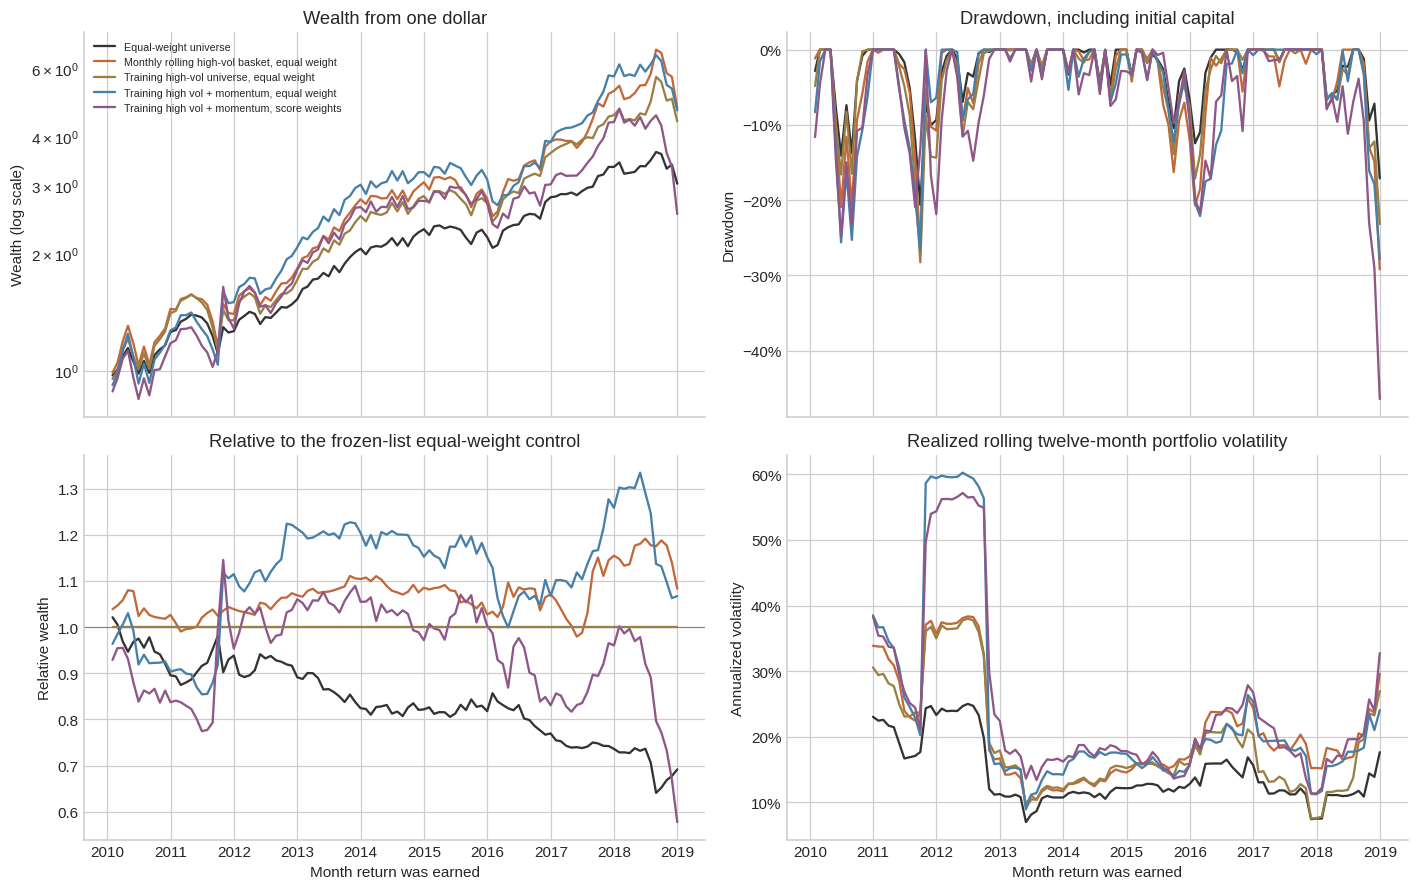

In [4]:
focus = ['equal_weight_universe', 'high_volatility', *HYBRID_LABELS]
colors = dict(zip(focus, ['#333333', '#c26939', '#9a7f45', '#477fa8', '#8f5688']))
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2), sharex=True)
parent = result['books']['training_high_vol_equal_weight']
for name in focus:
    book = all_books[name]
    axes[0, 0].plot(book.index, book.wealth, label=labels[name], color=colors[name])
    axes[0, 1].plot(book.index, book.drawdown, color=colors[name])
    axes[1, 0].plot(book.index, book.wealth / parent.wealth, color=colors[name])
    axes[1, 1].plot(book.index, book.simple_return.rolling(12).std(ddof=1) * np.sqrt(12), color=colors[name])
axes[0, 0].set_yscale('log')
axes[0, 0].set(title='Wealth from one dollar', ylabel='Wealth (log scale)')
axes[0, 0].legend(fontsize=7)
axes[0, 1].set(title='Drawdown, including initial capital', ylabel='Drawdown')
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 0].axhline(1, color='gray', lw=0.7)
axes[1, 0].set(title='Relative to the frozen-list equal-weight control', ylabel='Relative wealth')
axes[1, 1].set(title='Realized rolling twelve-month portfolio volatility', ylabel='Annualized volatility')
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes[1]:
    ax.set_xlabel('Month return was earned')
save_figure(fig, '01_hybrid_comparison')

## 4. Is the hybrid diversified, and what does it trade?

The number of holdings counts selected stocks. The effective number of holdings,
1 / sum of squared weights, also accounts for concentration. The score-weighted
hybrid can hold many stocks while depending heavily on a few extreme winners.
Momentum uses known returns, but a large historical winner does not guarantee a
large next-month return.

The first-decision table omits forward returns. Training volatility defines
membership, while trailing monthly momentum defines the new allocation.

,avg_names,avg_effective_n,largest_single_weight,avg_one_way_turnover,fallback_months
strategy,,,,,
"Training high-vol universe, equal weight",236.6852,236.6852,0.0046,0.0400,0
"Training high vol + momentum, equal weight",47.5648,47.5648,0.0227,0.2485,0
"Training high vol + momentum, score weights",47.5648,24.6962,0.4055,0.2125,0


,stock_id,training_volatility,trailing_momentum,training_high_vol_momentum_equal,training_high_vol_momentum_weighted
219,221,8.6182,45.9397,0.0208,0.1897
672,683,3.2224,36.8109,0.0208,0.1520
107,108,3.1411,19.8390,0.0208,0.0819
112,113,2.8500,16.4579,0.0208,0.0680
849,862,3.4246,15.4741,0.0208,0.0639
160,162,1.1773,11.0277,0.0208,0.0455
780,792,0.7816,8.8120,0.0208,0.0364
151,153,0.8682,4.2282,0.0208,0.0175
668,679,0.7783,3.5913,0.0208,0.0148
933,949,0.6809,3.3153,0.0208,0.0137


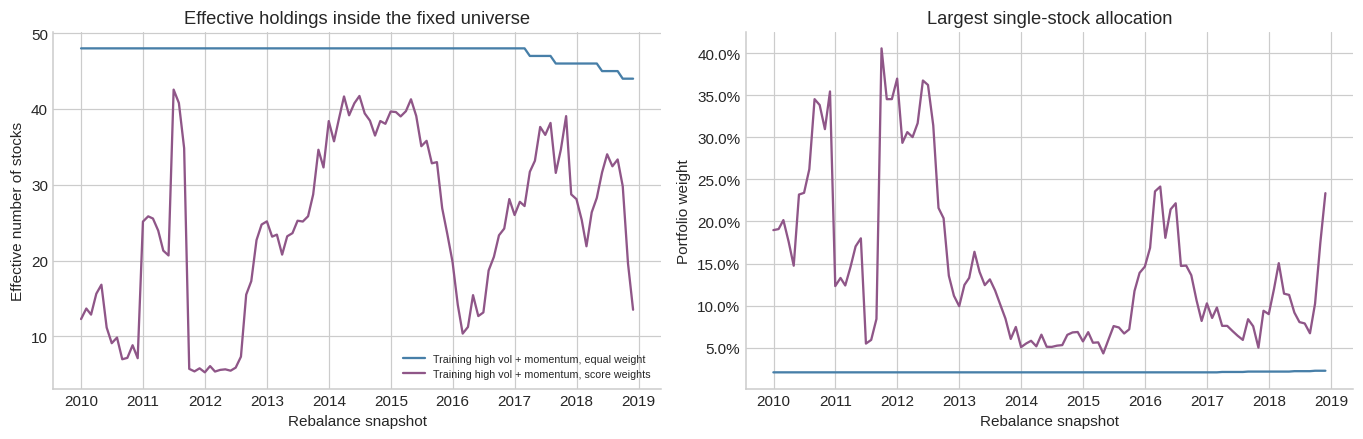

In [5]:
diag_columns = ['avg_names', 'avg_effective_n', 'largest_single_weight', 'avg_one_way_turnover', 'fallback_months']
diag = result['metrics'].set_index('strategy')[diag_columns]
diag.index = diag.index.map(HYBRID_LABELS)
display(diag.round(4))
example = signals.loc[signals.date.eq(boundary)].merge(
    ranking[['stock_id', 'training_volatility', 'selected']], on='stock_id', how='left', validate='many_to_one',
).merge(result['weights'], on=['date', 'stock_id'], validate='one_to_one')
example = example.loc[example.training_high_vol_momentum_weighted.gt(0)].sort_values(
    ['trailing_momentum', 'stock_id'], ascending=[False, True],
)
example.to_csv(OUT / 'first_hybrid_allocation.csv', index=False)
display(example[['stock_id', 'training_volatility', 'trailing_momentum',
                 'training_high_vol_momentum_equal', 'training_high_vol_momentum_weighted']].head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
for name in ['training_high_vol_momentum_equal', 'training_high_vol_momentum_weighted']:
    rows = audit.loc[audit.strategy.eq(name)]
    axes[0].plot(rows.date, rows.effective_n, color=colors[name], label=labels[name])
    axes[1].plot(rows.date, rows.max_weight, color=colors[name])
axes[0].set(title='Effective holdings inside the fixed universe', ylabel='Effective number of stocks', xlabel='Rebalance snapshot')
axes[0].legend(fontsize=7)
axes[1].set(title='Largest single-stock allocation', ylabel='Portfolio weight', xlabel='Rebalance snapshot')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, '02_hybrid_concentration')

## 5. Compare complete years and record the result

The test period was already examined before this idea was proposed. This
addition is a requested historical experiment, not an untouched confirmation.
Compare the same selected basket under equal and score weights before deciding
that either the volatility screen or momentum weighting is helpful.

The original baseline outputs are retained. The files for this addition live
under `outputs/hybrid/`, including the frozen list, rules, monthly returns,
allocation diagnostics, weights, and the complete comparison table.

In [6]:
yearly_rows = []
for name, book in all_books.items():
    annual = (1 + book.simple_return).groupby(book.index.year).prod() - 1
    yearly_rows.extend({'strategy': name, 'year': year, 'simple_return': value} for year, value in annual.items())
yearly = pd.DataFrame(yearly_rows)
yearly.to_csv(OUT / 'calendar_year_returns.csv', index=False)
year_table = yearly.loc[yearly.strategy.isin(focus)].pivot(index='year', columns='strategy', values='simple_return').reindex(columns=focus)
year_table.columns = year_table.columns.map(labels)
display(year_table.map(lambda x: f'{x:.1%}'))

comparison.to_csv(OUT / 'strategy_comparison.csv', index=False)
result['monthly'].to_csv(OUT / 'hybrid_monthly_returns.csv', index=False)
audit.to_csv(OUT / 'hybrid_allocation_diagnostics.csv', index=False)
result['weights'].to_csv(OUT / 'hybrid_weights.csv.gz', index=False, compression={'method':'gzip', 'mtime':0, 'compresslevel':3})
files = [ROOT / 'mlfactor_long_only_train.csv', ROOT / 'mlfactor_long_only_test.csv',
         ROOT / 'part0_data_and_benchmark' / 'pipeline.py', HERE / 'strategies.py', HERE / 'hybrid.py', HERE / '04_hybrid_rules.md']
manifest = {
    'source_sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in files},
    'frozen_list_sha256': hashlib.sha256((OUT / 'frozen_high_volatility_universe.csv').read_bytes()).hexdigest(),
    'specification': spec,
    'libraries': {'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'matplotlib':matplotlib.__version__},
    'window': 'January 2010 through December 2018',
    'test_status': 'Previously examined historical sample; new requested experiment',
}
(OUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')

ix = comparison.set_index('strategy')
hybrid = ix.loc['training_high_vol_momentum_weighted']
equal = ix.loc['training_high_vol_momentum_equal']
parent_stats = ix.loc['training_high_vol_equal_weight']
lines = ['# Training high volatility plus monthly momentum: executed findings', '',
         'Source: `05_high_volatility_momentum.ipynb`. Rule specification: `04_hybrid_rules.md`.', '',
         f'The fixed screen contains {len(frozen_ids)} stocks from {len(ranking)} with enough training history. Membership uses the 2000–2009 training returns only, and is frozen for the test period.', '',
         'Monthly momentum selection takes up to the top 20% of eligible screened names with positive twelve-month returns. Scores determine weights without a cap. Gross results use risk-free return zero.', '',
         '## January 2010–December 2018', '',
         '| Strategy | CAGR | Volatility | Sharpe | Max drawdown | Average names |',
         '| --- | --- | --- | --- | --- | --- |']
for name in ['equal_weight_universe', 'high_volatility', 'momentum_weighted', *HYBRID_LABELS]:
    row = ix.loc[name]
    lines.append(f'| {labels[name]} | {row.cagr:.2%} | {row.annualized_volatility:.2%} | {row.sharpe:.3f} | {row.max_drawdown:.2%} | {row.avg_names:.1f} |')
lines.extend(['',
    f'- Hybrid score weighting versus the frozen-list equal-weight control: CAGR difference {100*(hybrid.cagr-parent_stats.cagr):+.2f} percentage points, Sharpe difference {hybrid.sharpe-parent_stats.sharpe:+.3f}.',
    f'- Score weighting versus equal weights on the SAME selected momentum names: CAGR difference {100*(hybrid.cagr-equal.cagr):+.2f} percentage points, Sharpe difference {hybrid.sharpe-equal.sharpe:+.3f}.',
    f'- The score-weighted hybrid averages {hybrid.avg_names:.1f} actual holdings and {hybrid.avg_effective_n:.1f} effective holdings. Its largest single-stock weight is {hybrid.largest_single_weight:.2%}; average one-way turnover is {hybrid.avg_one_way_turnover:.2%}.',
    f'- Recorded hybrid fallback months: {int(hybrid.fallback_months)}.', '',
    '## Interpretation', '',
    'The frozen training screen and monthly rolling high-volatility basket are different rules. The two controls separate changes in the candidate universe, monthly selection, and capital allocation. Compare reward, drawdowns, concentration, and turnover together rather than only final wealth.', '',
    'The final training screen is not applied retrospectively to earlier training years. An honest training process check would refit it at earlier origins. The current result is a historical test-period comparison requested after earlier test results were seen, not fresh validation.', '',
    'Source returns retain extreme observations. No parameter tuning, return clipping, cash timing, weight cap, or original-feature selection was added. Original basic-strategy results, Part 0, and Part 1 were preserved.'])
(HERE / '06_hybrid_findings.md').write_text('\n'.join(lines) + '\n')
display(Markdown(f'**Hybrid: CAGR {hybrid.cagr:.2%}, volatility {hybrid.annualized_volatility:.2%}, Sharpe {hybrid.sharpe:.3f}, maximum drawdown {hybrid.max_drawdown:.2%}.**'))
display(Markdown('Saved [06_hybrid_findings.md](06_hybrid_findings.md) and the detailed experiment outputs.'))

strategy,Equal-weight universe,"Monthly rolling high-vol basket, equal weight","Training high-vol universe, equal weight","Training high vol + momentum, equal weight","Training high vol + momentum, score weights"
year,,,,,
2010,25.8%,44.2%,40.5%,26.9%,17.6%
2011,0.4%,-3.0%,-4.2%,18.2%,9.1%
2012,20.9%,30.9%,27.2%,38.5%,41.5%
2013,34.9%,50.7%,45.9%,44.8%,45.1%
2014,12.2%,10.6%,12.5%,7.7%,3.7%
2015,-4.6%,-9.3%,-4.2%,-4.2%,-1.1%
2016,26.7%,40.4%,34.6%,24.8%,11.5%
2017,19.7%,34.9%,25.1%,47.5%,44.7%
2018,-9.5%,-9.6%,-3.6%,-18.3%,-42.0%


**Hybrid: CAGR 10.86%, volatility 29.06%, Sharpe 0.494, maximum drawdown -46.44%.**

Saved [06_hybrid_findings.md](06_hybrid_findings.md) and the detailed experiment outputs.